# Part 2: Compare learning settings

This notebook reproduces the MsPacMan comparison described in the team's unchanged Part 1 predictions. Run from `notebooks/assignment4/` with the environment installed from the root `requirements.txt`.

We compare tabular Q-learning with a coarse object representation against PPO with the same underlying information represented more finely. Success means earning at least 2,000 new game points before losing all lives or reaching the finite decision limit. The team confirmed that game-score rewards in A/B were agreed with the instructor, adapting the brief's terminal-only reward wording. C adds a step penalty; D freezes the B agents and changes the maze.

All interaction uses the Gymnasium `reset(seed=...)` and five-return-value `step(action)` API. ALE RAM access is confined to the Gymnasium wrapper for object features and the map intervention. No assessed results are fabricated or inferred from the predictions.


## Environment and protocol

`mspacman_env.py` implements the finite-horizon score task. `rl_agents.py` implements off-policy tabular Q-learning and on-policy clipped actor-critic PPO. `part2_experiment.py` controls selection, training and frozen evaluation. `part2_report.py` turns the saved measurements into the report's inline tables and vector learning curve.

Training/development use maze selector 0; D uses selector 1. Natural map transitions raise an error, protecting the map holdout. The 15 features include position, nearest ghost and pellet offsets/distances, directional pellet counts, the internal power countdown, facing direction and time left. The power counter is not a claimed measurement in seconds. The two representations and omitted game state limit an algorithm-only interpretation.


In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image

HERE = Path.cwd().resolve()
assert (HERE / 'part2_experiment.py').is_file(), 'Run from notebooks/assignment4/.'
ROOT = HERE.parents[1]
RUN_ID = 'part2_controlled_v2'
RESULTS = ROOT / 'results/assignment4' / RUN_ID

def run_command(command):
    process = subprocess.Popen(
        [sys.executable, '-B', str(HERE / 'part2_experiment.py'), command, '--run-id', RUN_ID],
        cwd=HERE, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, encoding='utf-8', errors='replace',
        env={**os.environ, 'PYTHONUTF8': '1'})
    for line in process.stdout:
        print(line, end='', flush=True)
    if process.wait():
        raise RuntimeError(f'Part 2 command failed: {command}')


## Gymnasium and learning checks

The audit checks reset/step contracts and reproducibility, terminal success and time-limit failures, changed map geometry, identical B/C trajectories at fixed seeds/actions with only the reward changed, unchanged model parameters and training RNG during evaluation, NumPy/Torch PPO inference agreement, and actual updates of both agents. These small engineering checks are separate from assessed training runs.


In [2]:
run_command('audit')


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)


[Powered by Stella]


C:\Users\fredr\Documents\MIDT\IT3212\.venv\Lib\site-packages\gymnasium\utils\env_checker.py:445: UserWarning: WARN: The environment (<MsPacmanTask<OrderEnforcing<PassiveEnvChecker<AtariEnv<ALE/MsPacman-v5>>>>>) is different from the unwrapped version (<AtariEnv<ALE/MsPacman-v5>>). This could effect the environment checker as the environment most likely has a wrapper applied to it. We recommend using the raw environment for `check_env` using `env.unwrapped`.


  logger.warn(


AUDIT PASSED: Gymnasium contract, horizon, map change, frozen evaluation and PPO inference.


In [3]:
# Separate engineering diagnostic: verify the internal power countdown.
# Teleportation is used only in this diagnostic, never in assessed trajectories.
import numpy as np
from PIL import Image as PILImage
from mspacman_env import MsPacmanTask, TaskConfig

AUDIT = ROOT / 'results/assignment4/engineering_audit'
AUDIT.mkdir(parents=True, exist_ok=True)
power_env = MsPacmanTask(TaskConfig('A'), render_mode='rgb_array')
try:
    power_env.reset(seed=123)
    for _ in range(80):
        power_env.step(0)
    initial_bits = int(power_env.ram[117] & 60)
    power_env.unwrapped.ale.setRAM(10, 25)
    power_env.unwrapped.ale.setRAM(16, 146)
    power_rows = []
    for step in range(161):
        _, reward, terminated, truncated, info = power_env.step(3 if step < 15 else 0)
        power_rows.append({'step':step, 'power_bits':int(power_env.ram[117] & 60),
                           'countdown':int(power_env.ram[116])})
        if step in (0,80,160):
            PILImage.fromarray(power_env.render()).save(AUDIT / f'power_countdown_{step}.png')
        assert not (terminated or truncated)
    power = pd.DataFrame(power_rows)
    assert power.power_bits.iloc[0] != initial_bits
    assert 0 < power.countdown.iloc[0] <= 63
    assert power.countdown.iloc[80] < power.countdown.iloc[0]
    assert power.countdown.iloc[-1] == 0
    power.to_csv(AUDIT / 'power_countdown_validation.csv', index=False)
    display(power.iloc[[0,80,160]])
finally:
    power_env.close()


,step,power_bits,countdown
0,0,44,61
80,80,44,21
160,160,44,0


## Equal search allowance, then locked training and evaluation

For each A/B/C condition and algorithm, compare two learning rates using 16,384 interactions per candidate, a separate tuning training seed and 50 development evaluation episodes. Choose ONE common learning rate per algorithm from mean development success across A/B/C, then mean game score. This keeps all other settings fixed when A/B/C change. The design corrects an initial per-setting pilot after partial evaluation inspection; no final outcomes select rates, and the reused evaluation seeds are not a new independent test.

Each final agent trains for 65,536 decisions with seeds 42, 7 and 2026. Five checkpoints use 20 development episodes each to show learning against interactions. The final comparison uses 200 held-out episodes per trained agent and condition. Q-learning uses greedy actions with seeded uniform tie-breaking; PPO uses highest-probability actions. D reuses B weights/Q-tables without additional training.

The default command uses at most three CPU workers and one numerical thread per worker. It writes configurations, raw per-episode records, update histories, checkpoints, evaluation traces, source hashes and runtime/software provenance. Rerunning completed jobs reuses their saved measurements; changed code/protocol requires a new run ID. This cell can take substantial time on a new run.


In [4]:
run_command('run')


{"stage": "tuning", "algorithm": "Q-learning", "setting": "A", "seed": 31415, "success": 0.0, "score": 765.4, "completed": 1, "total": 12}


{"stage": "tuning", "algorithm": "Q-learning", "setting": "A", "seed": 31415, "success": 0.0, "score": 541.2, "completed": 2, "total": 12}


{"stage": "tuning", "algorithm": "PPO", "setting": "A", "seed": 31415, "success": 0.0, "score": 60.0, "completed": 3, "total": 12}


{"stage": "tuning", "algorithm": "Q-learning", "setting": "B", "seed": 31415, "success": 0.02, "score": 677.4, "completed": 4, "total": 12}


{"stage": "tuning", "algorithm": "Q-learning", "setting": "B", "seed": 31415, "success": 0.0, "score": 443.6, "completed": 5, "total": 12}


{"stage": "tuning", "algorithm": "PPO", "setting": "B", "seed": 31415, "success": 0.0, "score": 60.0, "completed": 6, "total": 12}


... (21 outputs left out)

{"stage": "final", "algorithm": "PPO", "setting": "C", "seed": 42, "success": 0.0, "score": 60.0, "completed": 16, "total": 18}


{"stage": "final", "algorithm": "PPO", "setting": "C", "seed": 7, "success": 0.0, "score": 70.0, "completed": 17, "total": 18}


{"stage": "final", "algorithm": "PPO", "setting": "C", "seed": 2026, "success": 0.0, "score": 60.0, "completed": 18, "total": 18}


Rendered measured Part 2 report and learning curve: part2_controlled_v2


In [5]:
protocol = json.loads((RESULTS / 'protocol.json').read_text())
selected = json.loads((RESULTS / 'selected_parameters.json').read_text())
environment = json.loads((RESULTS / 'environment.json').read_text())
display(pd.DataFrame([
    {'setting': setting, 'maze': task['maze'], 'sticky_probability': task['sticky_probability'],
     'reward': 'score increment - 0.1 per decision' if setting == 'C' else 'score increment',
     'new_training': setting != 'D'}
    for setting, task in protocol['tasks'].items()
]))
print('Selected learning rates:', selected)
print('CPU:', environment['cpu'])
print('Recorded versions:', environment['packages'])


,setting,maze,sticky_probability,reward,new_training
0,A,0,0.00,score increment,True
1,B,0,0.25,score increment,True
2,C,0,0.25,score increment - 0.1 per decision,True
3,D,1,0.25,score increment,False


Selected learning rates: {'A_Q-learning': {'learning_rate': 0.1}, 'B_Q-learning': {'learning_rate': 0.1}, 'C_Q-learning': {'learning_rate': 0.1}, 'A_PPO': {'learning_rate': 0.001}, 'B_PPO': {'learning_rate': 0.001}, 'C_PPO': {'learning_rate': 0.001}}
CPU: Intel(R) Core(TM) Ultra 7 258V
Recorded versions: {'numpy': '2.5.4', 'pandas': '3.1.1', 'torch': '2.14.1+cpu', 'gymnasium': '1.4.0', 'ale-py': '0.12.1', 'matplotlib': '3.11.2', 'threadpoolctl': '3.6.0'}


## Measured performance, episode lengths and computation

Keep the independently trained agent as the replication unit. The tables show mean and sample SD across three training seeds; the 200 evaluation episodes for one model are not 200 independent training replications. Lengths are conditional on success/failure, so an absent outcome has no defined mean length. D's training cost belongs to its B source agent; its additional training budget is zero.


In [6]:
records = json.loads((RESULTS / 'final_summary.json').read_text())
rows = []
for record in records:
    rows.append({key: value for key, value in record.items() if key != 'transfer'})
    if record['setting'] == 'B':
        rows.append({**rows[-1], **record['transfer'], 'setting':'D',
                     'train_seconds':0, 'training_interactions':0})
per_agent = pd.DataFrame(rows)
metrics = ['success_rate', 'failure_rate', 'mean_score', 'mean_return',
           'success_length', 'failure_length', 'train_seconds', 'evaluation_seconds']
display(per_agent.groupby(['setting','algorithm'])[metrics].agg(['mean','std']))
display(per_agent[['setting','algorithm','seed','training_interactions',
                   'evaluation_episodes','time_limit_failures']].sort_values(['setting','algorithm','seed']))
assert per_agent.evaluation_episodes.eq(200).all()
assert len(per_agent) == 24


success_rate           failure_rate            mean_score  \
                           mean       std         mean       std        mean   
setting algorithm                                                              
A       PPO            0.000000  0.000000     1.000000  0.000000   83.333333   
        Q-learning     0.010000  0.013229     0.990000  0.013229  742.783333   
B       PPO            0.000000  0.000000     1.000000  0.000000  179.966667   
        Q-learning     0.003333  0.005774     0.996667  0.005774  708.600000   
C       PPO            0.000000  0.000000     1.000000  0.000000   63.333333   
        Q-learning     0.005000  0.000000     0.995000  0.000000  857.566667   
D       PPO            0.000000  0.000000     1.000000  0.000000  143.333333   
        Q-learning     0.000000  0.000000     1.000000  0.000000  206.633333   

                               mean_return             success_length  \
                           std        mean         std           mean   
setting algorithm                                                       
A       PPO          32.145503   83.333333   32.145503            NaN   
        Q-learning  115.406427  742.783333  115.406427          564.0   
B       PPO          98.447973  179.966667   98.447973            NaN   
        Q-learning   75.860777  708.600000   75.860777          432.0   
C       PPO           5.773503   13.833333    3.695042            NaN   
        Q-learning  287.477309  789.494167  276.427650          636.0   
D       PPO          61.101009  143.333333   61.101009            NaN   
        Q-learning   48.070478  206.633333   48.070478            NaN   

                              failure_length             train_seconds  \
                          std           mean         std          mean   
setting algorithm                                                        
A       PPO               NaN     520.333333   38.017540    100.670024   
        Q-learning  26.870058     655.005492   59.781983     69.682239   
B       PPO               NaN     580.853333  134.359758     43.745880   
        Q-learning        NaN     654.919596   15.014739     78.167523   
C       PPO               NaN     495.000000   20.784610     72.834371   
        Q-learning  98.045908     680.949749  112.935007     63.866770   
D       PPO               NaN     562.986667  103.308860      0.000000   
        Q-learning        NaN     524.740000   27.949649      0.000000   

                              evaluation_seconds             
                          std               mean        std  
setting algorithm                                            
A       PPO          0.528978          84.674509   9.515256  
        Q-learning   0.704273         123.042931   3.104694  
B       PPO          2.302782          54.188169   8.997995  
        Q-learning   0.265831          81.403190   6.570739  
C       PPO         11.175890          73.632596  32.261680  
        Q-learning   1.940414          96.292424  13.012201  
D       PPO          0.000000          53.427253  10.079013  
        Q-learning   0.000000          54.880776   2.103454

,setting,algorithm,seed,training_interactions,evaluation_episodes,time_limit_failures
3,A,PPO,7,65536,200,0
4,A,PPO,42,65536,200,0
11,A,PPO,2026,65536,200,0
2,A,Q-learning,7,65536,200,4
0,A,Q-learning,42,65536,200,0
1,A,Q-learning,2026,65536,200,0
12,B,PPO,7,65536,200,0
9,B,PPO,42,65536,200,0
16,B,PPO,2026,65536,200,0
14,B,Q-learning,7,65536,200,3


## Learning curves and interpretation

Curves use separate development episodes, no smoothing, and one sample SD across training seeds. Final held-out episodes do not select settings or contribute to the learning curves. Compare B/C with common game points and success/failure, since C's penalised return has a different definition.


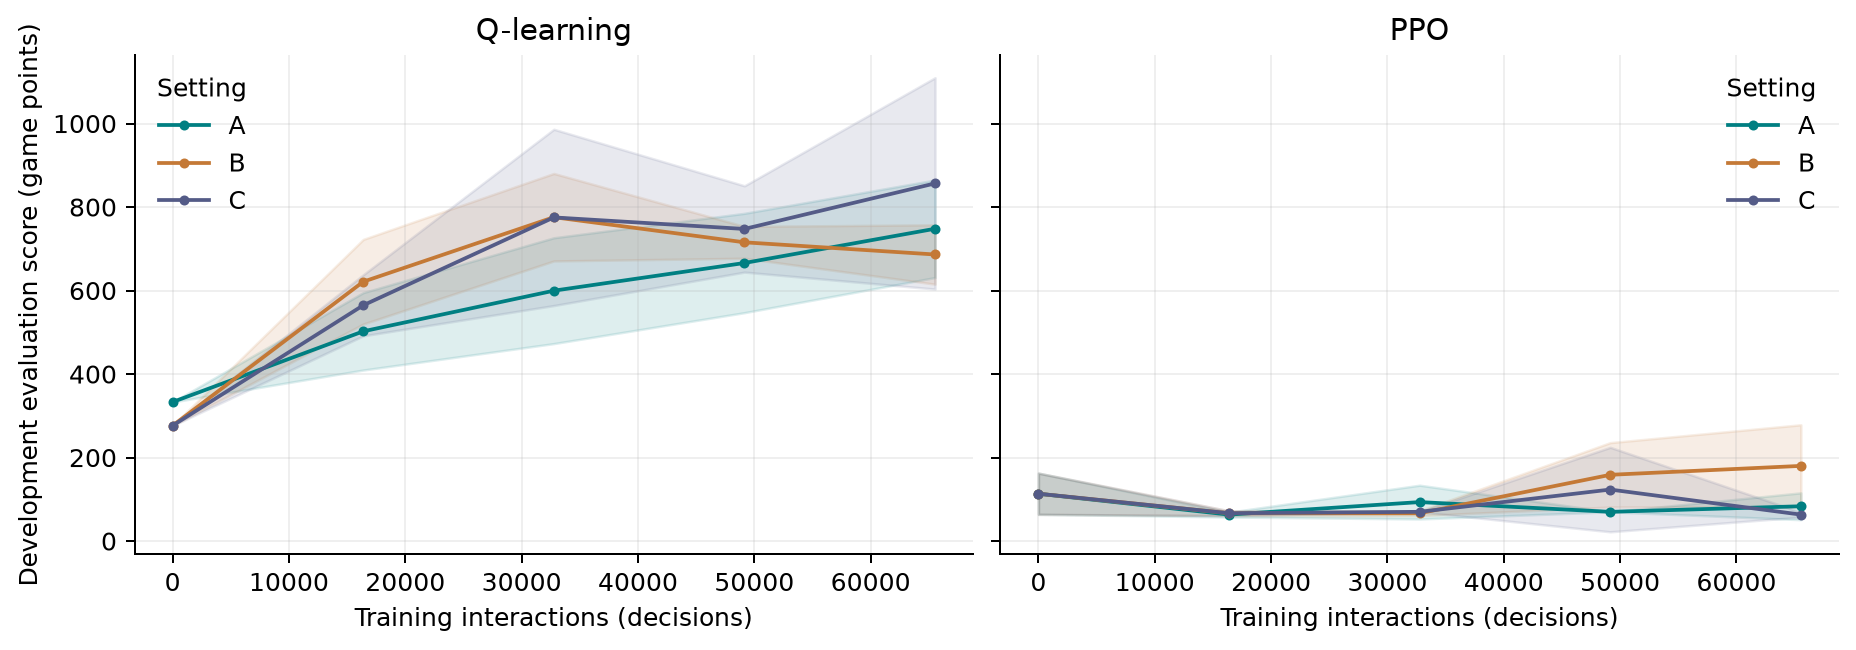

In [7]:
display(Image(filename=str(RESULTS / 'previews/part2_learning_curves.png')))


In [8]:
means = pd.read_csv(RESULTS / 'condition_means.csv').set_index(['setting','algorithm'])
for algorithm in ('Q-learning','PPO'):
    print(algorithm)
    for setting in 'ABCD':
        row = means.loc[(setting, algorithm)]
        print(f'  {setting}: mean score {row.mean_score:.1f} game points; '
              f'success {100*row.success_rate:.1f}%; return {row.mean_return:.1f} points')
if per_agent.success_rate.eq(0).all():
    print('No final evaluation episode met the 2,000-point target. '
          'Score differences show partial progress, not demonstrated reliability.')
print('The report section and figure were refreshed from these measured exports.')


Q-learning
  A: mean score 742.8 game points; success 1.0%; return 742.8 points
  B: mean score 708.6 game points; success 0.3%; return 708.6 points
  C: mean score 857.6 game points; success 0.5%; return 789.5 points
  D: mean score 206.6 game points; success 0.0%; return 206.6 points
PPO
  A: mean score 83.3 game points; success 0.0%; return 83.3 points
  B: mean score 180.0 game points; success 0.0%; return 180.0 points
  C: mean score 63.3 game points; success 0.0%; return 13.8 points
  D: mean score 143.3 game points; success 0.0%; return 143.3 points
The report section and figure were refreshed from these measured exports.


### Scope of conclusions

The budget studies early learning and does not establish convergence. Three training seeds and two candidates per algorithm/condition limit robustness claims. Coarse versus finer observations mean this is a workflow comparison. A changed ROM map can also alter layout-dependent game behaviour, so D is not a clean geometry-only intervention. Neither a higher mean return nor shorter episodes alone proves a higher success rate or safer behaviour. Preserve Part 1 and place later prediction annotations separately.

The completed Part 2 text is in `reports/assignment4/Sections/02_learning_settings.tex`. Original measurements remain in `results/assignment4/part2_controlled_v2/`; final per-decision traces include native RAM, Q-values or policy probabilities, actions, rewards and episode/step IDs for later episode inspection. The report is not compiled automatically.
